In [326]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [327]:
# Фиксируем seed и выбираем устройство
torch.manual_seed(1)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [328]:
data = pd.read_csv('./data/processed/train.csv')

X = data.drop(columns=['Survived'])
y = data['Survived']

# После get_dummies колонки bool — переводим в int для тензоров
X['Embarked_Q'] = X['Embarked_Q'].astype(int)
X['Embarked_S'] = X['Embarked_S'].astype(int)

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [330]:
X_train = torch.tensor(X_train.values, dtype=torch.float32, device=device)
X_val = torch.tensor(X_val.values, dtype=torch.float32, device=device)
y_train = torch.tensor(y_train.values, dtype=torch.long, device=device)
y_val = torch.tensor(y_val.values, dtype=torch.long, device=device)

In [331]:
# Датасет и загрузчик с батчами по 16
train_dataset = TensorDataset(X_train, y_train)

In [332]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

In [333]:
# MLP: один скрытый слой на 64 нейрона + ReLU + Dropout
class TitanicClassifier(nn.Module):
    def __init__(self, input, output):
        super().__init__()
        self.layer_1 = nn.Linear(input, 64)
        self.layer_2 = nn.Linear(64, 2)
        self.dropout = nn.Dropout(p=0.2)
        self.act = nn.ReLU()
        
    def forward(self, x):
        x = self.layer_1(x)
        x = self.act(x)
        x = self.dropout(x)
        out = self.layer_2(x) 
        
        return out

model = TitanicClassifier(X_train.shape[1], 2).to(device)
model

TitanicClassifier(
  (layer_1): Linear(in_features=10, out_features=64, bias=True)
  (layer_2): Linear(in_features=64, out_features=2, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (act): ReLU()
)

In [334]:
# Проверяем размер выхода на случайном батче
input = torch.rand([16, 10], dtype=torch.float32, device=device)

model(input).shape

torch.Size([16, 2])

In [335]:
# CrossEntropy для 2 классов, оптимизатор Adam
loss_model = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=0.001)

In [336]:
EPOCHS = 50
train_loss = []
train_acc = []
val_loss = []
val_acc = []
best_val_loss = float('inf')

for epoch in range(EPOCHS):
    # Обучение по батчам
    model.train()
    for x, targets in train_loader:
        pred = model(x)
        
        opt.zero_grad()
        
        loss = loss_model(pred, targets)
        loss.backward()
        opt.step()
    
    # После эпохи считаем loss и accuracy на train и val
    model.eval()
    with torch.no_grad():
        train_pred = model(X_train)
        train_loss.append(loss_model(train_pred, y_train).item())
        train_acc.append((train_pred.argmax(dim=1) == y_train).float().mean().item())
        
        val_pred = model(X_val)
        
        loss = loss_model(val_pred, y_val)
    
        val_loss.append(loss.item())
        val_acc.append((val_pred.argmax(dim=1) == y_val).sum().item() / len(y_val))
    
        # Сохраняем веса с лучшим val loss
        if loss < best_val_loss:
            best_val_loss = loss.item()
            torch.save(model.state_dict(), 'best_model.pt')
            print(f'model saved on {epoch + 1} epoch')
            

model saved on 1 epoch
model saved on 2 epoch
model saved on 3 epoch
model saved on 4 epoch
model saved on 5 epoch
model saved on 6 epoch
model saved on 7 epoch
model saved on 8 epoch
model saved on 9 epoch
model saved on 10 epoch
model saved on 11 epoch
model saved on 12 epoch
model saved on 15 epoch
model saved on 16 epoch
model saved on 18 epoch
model saved on 20 epoch
model saved on 22 epoch
model saved on 23 epoch
model saved on 24 epoch
model saved on 25 epoch
model saved on 27 epoch
model saved on 31 epoch
model saved on 36 epoch


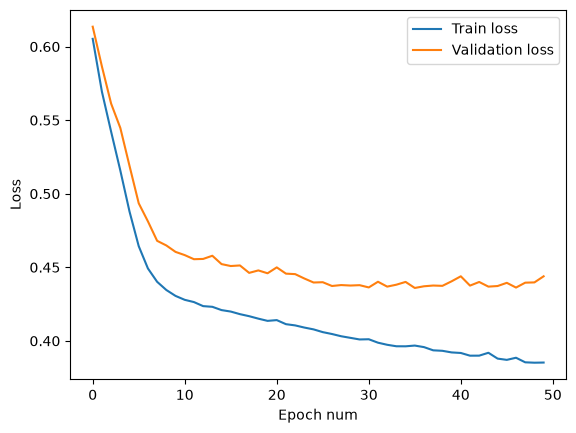

In [337]:
# Кривые обучения
sns.lineplot(train_loss, label='Train loss')
sns.lineplot(val_loss, label='Validation loss')
plt.xlabel('Epoch num')
plt.ylabel('Loss');

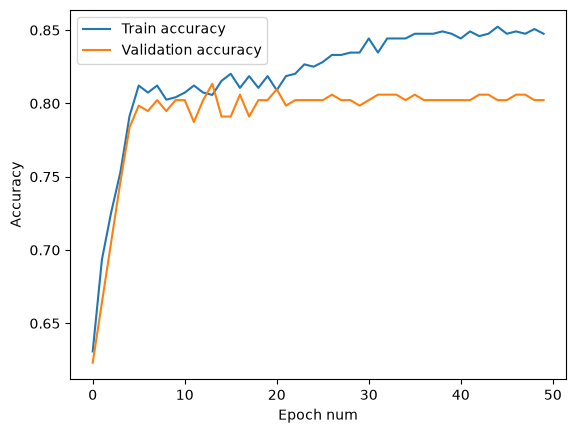

In [338]:
sns.lineplot(train_acc, label='Train accuracy')
sns.lineplot(val_acc, label='Validation accuracy')
plt.xlabel('Epoch num')
plt.ylabel('Accuracy');

In [339]:
# Предсказание на test лучшей моделью и сабмит
test_data = pd.read_csv('./data/processed/test.csv')
raw_test_df = pd.read_csv('./data/raw/test.csv')

test_data['Embarked_Q'] = test_data['Embarked_Q'].astype(int)
test_data['Embarked_S'] = test_data['Embarked_S'].astype(int)

X = torch.tensor(test_data.values, dtype=torch.float32, device=device)

model.load_state_dict(
    torch.load('best_model.pt', map_location=device)
)
model.eval()

with torch.no_grad():
    pred = model(X).argmax(dim=1).cpu().numpy()
    
submission = pd.DataFrame({
    'PassengerId': raw_test_df['PassengerId'],
    'Survived': pred
})
submission.to_csv('./submissions/NNsubmission.csv', index=False)
# LB: 0.76794